<a href="https://colab.research.google.com/github/scottn66/vgg11/blob/main/vgg11_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rebuild VGG11 (Simonyan & Zisserman 2014, config A) and train it on

In [ ]:
import torch, torch.nn as nn
x = torch.randn(1, 3, 224, 224)
conv = nn.Conv2d(3, 64, kernel_size=3, padding=1)
print(conv(x).shape, sum(p.numel() for p in conv.parameters()))

torch.Size([1, 64, 224, 224]) 1792


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/data
!cp /content/drive/MyDrive/vgg11/data/imagenet_*20.zip /content/data/
%cd /content/data
!for z in imagenet_*20.zip; do unzip -q -o "$z"; done
!ls; ls imagenet_train20a | wc -l; ls imagenet_val20 | wc -l

Mounted at /content/drive
/content/data
imagenet_test20      imagenet_train20a	   imagenet_val20
imagenet_test20.zip  imagenet_train20.zip  imagenet_val20.zip
20
1000


In [ ]:
import torch, torch.nn as nn

x = torch.randn(1, 3, 224, 224)

# Lesson 1: one conv layer
conv = nn.Conv2d(3, 64, kernel_size=3, padding=1)
y = conv(x)
print("conv:", y.shape, sum(p.numel() for p in conv.parameters()))

# Lesson 2: one pool layer
pool = nn.MaxPool2d(2)
z = pool(y)
print("pool:", z.shape, sum(p.numel() for p in pool.parameters()))

conv: torch.Size([1, 64, 224, 224]) 1792
pool: torch.Size([1, 64, 112, 112]) 0


In [ ]:
import torch, torch.nn as nn

def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=(3,3), padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
    )

# check
b = conv_block(3, 64)
print(b(torch.randn(1, 3, 224, 224)).shape)       # expect (1, 64, 224, 224)
print(sum(p.numel() for p in b.parameters()))     # expect 1792

torch.Size([1, 64, 224, 224])
1920


In [ ]:
def max_pool_layer():
    return nn.MaxPool2d(kernel_size=2, stride=2)



In [ ]:
features = nn.Sequential(
    conv_block(3, 64),     nn.MaxPool2d(2, 2),
    conv_block(64, 128),   nn.MaxPool2d(2, 2),
    conv_block(128, 256),  conv_block(256, 256),  nn.MaxPool2d(2, 2),
    conv_block(256, 512),  conv_block(512, 512),  nn.MaxPool2d(2, 2),
    conv_block(512, 512),  conv_block(512, 512),  nn.MaxPool2d(2, 2),
)

# check
out = features(torch.randn(1, 3, 224, 224))
print(out.shape)                                       # expect (1, 512, 7, 7)
print(sum(p.numel() for p in features.parameters()))   # expect 9,220,480

torch.Size([1, 512, 7, 7])
9225984


In [ ]:
classifier = nn.Sequential(
    nn.Flatten(),
    nn.Linear(25088, 4096), nn.ReLU(),
    nn.Linear(4096, 4096), nn.ReLU(),
    nn.Linear(4096, 20),          # no softmax: CrossEntropyLoss handles it
)

# check
logits = classifier(torch.randn(1, 512, 7, 7))
print(logits.shape)                                      # expect (1, 20)
print(sum(p.numel() for p in classifier.parameters()))   # expect 119,627,796

torch.Size([1, 20])
119627796


In [ ]:
class VGG11(nn.Module):
    def __init__(self, num_classes=20):
        super().__init__()
        self.features = nn.Sequential(
                                    conv_block(3, 64),     nn.MaxPool2d(2, 2),
                                    conv_block(64, 128),   nn.MaxPool2d(2, 2),
                                    conv_block(128, 256),  conv_block(256, 256),  nn.MaxPool2d(2, 2),
                                    conv_block(256, 512),  conv_block(512, 512),  nn.MaxPool2d(2, 2),
                                    conv_block(512, 512),  conv_block(512, 512),  nn.MaxPool2d(2, 2),
                                )        # your features Sequential
        self.classifier = nn.Sequential(
                                    nn.Flatten(),
                                    nn.Linear(25088, 4096), nn.ReLU(),
                                    nn.Linear(4096, 4096), nn.ReLU(),
                                    nn.Linear(4096, num_classes),          # no softmax: CrossEntropyLoss handles it
                                )      # your classifier Sequential (last Linear uses num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# check
m = VGG11()
print(m(torch.randn(2, 3, 224, 224)).shape)      # expect (2, 20)
print(sum(p.numel() for p in m.parameters()))    # expect 128,848,276 (without BatchNorm)

torch.Size([2, 20])
128853780


In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
val_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_ds = datasets.ImageFolder("/content/data/imagenet_train20a", transform=train_tf)

class FlatVal(Dataset):
    def __init__(self, root, class_to_idx, tf):
        self.files = sorted(os.listdir(root))
        self.root, self.c2i, self.tf = root, class_to_idx, tf
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        name = self.files[i]                      # e.g. n01737021_10767.JPEG
        label = self.c2i[name.split("_")[0]]
        img = Image.open(os.path.join(self.root, name)).convert("RGB")
        return self.tf(img), label

val_ds = FlatVal("/content/data/imagenet_val20", train_ds.class_to_idx, val_tf)

# check
print(len(train_ds), len(val_ds), len(train_ds.classes))   # expect 6000 1000 20
x, y = train_ds[0]; print(x.shape, y)                       # expect (3, 224, 224) 0

6000 1000 20
torch.Size([3, 224, 224]) 0


In [ ]:
device = "cuda"
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=2)

model = VGG11().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)

x, y = next(iter(train_dl))
x, y = x[:8].to(device), y[:8].to(device)      # one tiny batch

for step in range(300):
    logits = model(x)
    loss = criterion(logits, y)
    optimizer.zero_grad()        # clear old gradients
    loss.backward()             # compute new gradients
    optimizer.step()        # update weights
    if step % 10 == 0:
        print(step, round(loss.item(), 4))

0 3.0023
10 0.01
20 0.0001
30 0.0001
40 0.0
50 0.0
60 0.0
70 0.0
80 0.0
90 0.0
100 0.0
110 0.0
120 0.0
130 0.0
140 0.0
150 0.0
160 0.0
170 0.0
180 0.0
190 0.0
200 0.0
210 0.0
220 0.0
230 0.0
240 0.0
250 0.0
260 0.0
270 0.0
280 0.0
290 0.0


In [ ]:
print(model.features[0])

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
)


In [ ]:
import time
model = VGG11().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4)
EPOCHS = 30
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def evaluate(model, loader):
    model.eval()                        # eval mode: BatchNorm uses running stats
    correct = total = 0
    with torch.no_grad():                  # no gradients needed for evaluation
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(dim=1)    # pick the highest logit per image
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

best = 0.0
for epoch in range(EPOCHS):
    model.train()                        # back to train mode
    t0, running = time.time(), 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = criterion(model(x), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        running += loss.item() * x.size(0)
    scheduler.step()                   # once per epoch
    train_loss = running / len(train_ds)
    val_acc = evaluate(model, val_dl)
    if val_acc > best:
        best = val_acc
        torch.save(model.state_dict(), "/content/drive/MyDrive/vgg11/runs/best.pt")
    print(f"epoch {epoch+1:2d}  loss {train_loss:.3f}  val acc {val_acc:.3f}  ({time.time()-t0:.0f}s)")

epoch  1  loss 2.633  val acc 0.242  (73s)
epoch  2  loss 2.349  val acc 0.298  (72s)
epoch  3  loss 2.239  val acc 0.385  (73s)
epoch  4  loss 2.090  val acc 0.272  (69s)
epoch  5  loss 1.987  val acc 0.360  (68s)
epoch  6  loss 1.899  val acc 0.362  (68s)
epoch  7  loss 1.844  val acc 0.447  (70s)
epoch  8  loss 1.772  val acc 0.465  (71s)
epoch  9  loss 1.680  val acc 0.510  (71s)
epoch 10  loss 1.631  val acc 0.552  (71s)
epoch 11  loss 1.556  val acc 0.507  (69s)
epoch 12  loss 1.492  val acc 0.576  (70s)
epoch 13  loss 1.423  val acc 0.536  (70s)
epoch 14  loss 1.356  val acc 0.557  (68s)
epoch 15  loss 1.319  val acc 0.591  (70s)
epoch 16  loss 1.225  val acc 0.633  (72s)
epoch 17  loss 1.203  val acc 0.645  (73s)
epoch 18  loss 1.145  val acc 0.623  (70s)
epoch 19  loss 1.074  val acc 0.654  (73s)
epoch 20  loss 1.037  val acc 0.684  (72s)
epoch 21  loss 1.002  val acc 0.671  (70s)
epoch 22  loss 0.947  val acc 0.703  (70s)
epoch 23  loss 0.926  val acc 0.725  (74s)
epoch 24  l

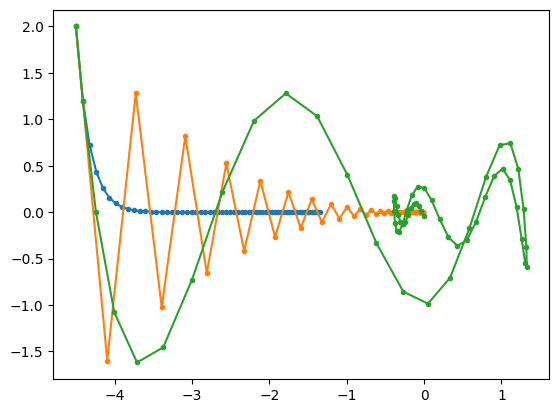

In [ ]:
import matplotlib.pyplot as plt
def loss_fn(w):
    x, y = w
    return 0.1 * x**2 + 2 * y**2
def run(make_opt, steps=60):
    w = torch.tensor([-4.5, 2.0], requires_grad=True)
    opt = make_opt([w])                 # build whichever optimizer we pass in
    path = [w.detach().clone()]
    for _ in range(steps):
        loss = loss_fn(w)
        opt.zero_grad(); loss.backward(); opt.step()
        path.append(w.detach().clone())
    return torch.stack(path).numpy()

optimizers = [
    ("SGD lr=0.1",      lambda p: torch.optim.SGD(p, lr=0.1)),
    ("SGD lr=0.45",     lambda p: torch.optim.SGD(p, lr=0.45)),
    ("SGD + momentum",  lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9)),
    # ("Adam lr=0.3",     lambda p: torch.optim.Adam(p, lr=0.3, betas=(0.9, 0.999))),
]
for label, make_opt in optimizers:
    p = run(make_opt)
    plt.plot(p[:, 0], p[:, 1], "o-", ms=3, label=label)